In [13]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
# [[18, 4, 4]]
l,m = 3, 3
a1,a2,a3 = 1, 0, 2
b1,b2,b3 = 1, 0, 2
n = 2*m*l;  n2 = m*l
I_l = np.identity(l, dtype=int) ; I_m = np.identity(m, dtype=int); I = np.identity(l*m, dtype=int)
x = {} ;  y = {}
for i in range(l):
	x[i] = np.kron(np.roll(I_l,i,axis=1),I_m)
for i in range(m):
	y[i] = np.kron(I_l,np.roll(I_m,i,axis=1))
A = (x[a1%l] + y[a2%m] + y[a3%m]) % 2
B = (y[b1%m] + x[b2%l] + x[b3%l]) % 2
A1 = x[a1%l]; A2 = y[a2%m]; A3 = y[a3%m]
B1 = y[b1%m]; B2 = x[b2%l]; B3 = x[b3%l]
AT = np.transpose(A) ; BT = np.transpose(B)
hx = np.hstack((A,B));  hz = np.hstack((BT,AT))


In [47]:
stabs = hx[0:7]

In [46]:
# To generate all possible errors
fallthrougherrors = 0
fallthrougherrorweights = []
p = 0.1
fallthrougherrorprobs = 0
elist = []
for i in tqdm(range(1, 2**(18))):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) != 6 and np.sum(bit) != 4 and np.sum(bit) != 8:
        #pass
        continue
    for row in stabs:
        if np.sum(bit*row) % 2 == 1:
            break
    else:
        fallthrougherrors += 1
        fallthrougherrorweights.append(np.sum(bit))
        fallthrougherrorprobs += p**np.sum(bit)
        elist.append(bit)
print(fallthrougherrors, fallthrougherrorprobs)


100%|██████████| 262143/262143 [00:01<00:00, 137050.20it/s]

1023 0.004809749999999991


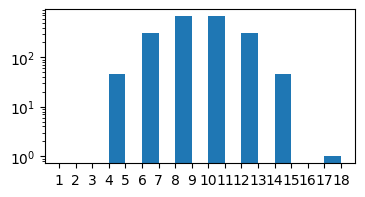

In [32]:
plt.figure(figsize = (4, 2))
plt.hist(fallthrougherrorweights, bins=range(1,19))
plt.xticks(range(1,19))
plt.yscale('log')
plt.show()

In [48]:
targetweight = 4
logicaloperators = []
for i in tqdm(range(2**18)):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) == targetweight:
        for row in stabs:
            if np.sum(bit*row) % 2 == 1:
                break
            elif np.equal(bit, row).all():
                break
        else:
            logicaloperators.append(bit)
print(len(logicaloperators))

100%|██████████| 262144/262144 [00:00<00:00, 291845.36it/s]

45


In [50]:
stabssingle = np.zeros((8, 18))
stabssingle[0:7] = stabs.copy()
stabssingle[7] = logicaloperators[0]
print(stabssingle)

[[1. 0. 1. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0.]
 [0. 1. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 1.]]


In [52]:
# Run algebraic enumeration of error space
p = 0.1
nfallthrougherrors = 0
fallthrougherrorweights = []
fallthrougherrorprobs = 0
thisstabs = stabssingle.copy()
for i in tqdm(range(1, 2**(18))):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) != 6 and np.sum(bit) != 4 and np.sum(bit) != 8:
        #pass
        continue
    for row in thisstabs:
        if np.sum(bit*row) % 2 == 1:
            break
    else:
        nfallthrougherrors += 1
        fallthrougherrorweights.append(np.sum(bit))
        fallthrougherrorprobs += p**np.sum(bit)
print(nfallthrougherrors, fallthrougherrorprobs)


100%|██████████| 262143/262143 [00:01<00:00, 140603.45it/s]

511 0.0022543899999999816


In [ ]:
errorlandscape = 